In [1]:
# Import libraries
import geopandas as gpd
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import folium
from branca.element import Template, MacroElement
import plotly.graph_objects as go

In [2]:
# Load UNOSAT building damage labels and AOI boundaries from GeoJSON files
labels = gpd.read_file("../data/raw/unosat/unosat_labels.geojson")
aois = gpd.read_file("../data/raw/unosat/unosat_aois.geojson")

print("Labels shape:", labels.shape)
print("AOIs shape: ", aois.shape)

Labels shape: (18686, 12)
AOIs shape:  (18, 2)


In [3]:
# Preview the first 10 labeled buildings to inspect column structure
labels.head(10)

,unosat_id,date,damage,layer,gdb,city,country,ep,prev_date,prev_damage,aoi,geometry
0,14955,2022-03-16 00:00:00+00:00,4,Makariv_CDA_20220316,CE20220223UKR_UNOSAT_Damage,Makariv,Ukraine,1,NaT,-99,UKR9,POINT (29.78955 50.44497)
1,14954,2022-03-16 00:00:00+00:00,3,Makariv_CDA_20220316,CE20220223UKR_UNOSAT_Damage,Makariv,Ukraine,1,NaT,-99,UKR9,POINT (29.79235 50.45955)
2,14957,2022-03-16 00:00:00+00:00,2,Makariv_CDA_20220316,CE20220223UKR_UNOSAT_Damage,Makariv,Ukraine,1,NaT,-99,UKR9,POINT (29.79629 50.4448)
3,14958,2022-03-16 00:00:00+00:00,4,Makariv_CDA_20220316,CE20220223UKR_UNOSAT_Damage,Makariv,Ukraine,1,NaT,-99,UKR9,POINT (29.79654 50.45014)
4,14956,2022-03-16 00:00:00+00:00,3,Makariv_CDA_20220316,CE20220223UKR_UNOSAT_Damage,Makariv,Ukraine,1,NaT,-99,UKR9,POINT (29.79677 50.44842)
5,14960,2022-03-16 00:00:00+00:00,4,Makariv_CDA_20220316,CE20220223UKR_UNOSAT_Damage,Makariv,Ukraine,1,NaT,-99,UKR9,POINT (29.79764 50.44767)
6,14959,2022-03-16 00:00:00+00:00,4,Makariv_CDA_20220316,CE20220223UKR_UNOSAT_Damage,Makariv,Ukraine,1,NaT,-99,UKR9,POINT (29.79764 50.45061)
7,14961,2022-03-16 00:00:00+00:00,2,Makariv_CDA_20220316,CE20220223UKR_UNOSAT_Damage,Makariv,Ukraine,1,NaT,-99,UKR9,POINT (29.79905 50.44639)
8,14965,2022-03-16 00:00:00+00:00,4,Makariv_CDA_20220316,CE20220223UKR_UNOSAT_Damage,Makariv,Ukraine,1,NaT,-99,UKR9,POINT (29.80149 50.46736)
9,14962,2022-03-16 00:00:00+00:00,1,Makariv_CDA_20220316,CE20220223UKR_UNOSAT_Damage,Makariv,Ukraine,1,NaT,-99,UKR9,POINT (29.80183 50.44748)


In [4]:
# Build a reference table of all UNOSAT damage classes with descriptions and Dietrich usage flags
damage_legend = pd.DataFrame([
    {
        "Code": 1,
        "Label": "Destroyed",
        "Description": "Building completely destroyed or collapsed. No structural elements remain intact.",
        "Used by Dietrich et al.": "Yes"
    },
    {
        "Code": 2,
        "Label": "Severely damaged",
        "Description": "Major structural damage to load-bearing walls or roof. Likely uninhabitable; requires full rebuild.",
        "Used by Dietrich et al.": "Yes"
    },
    {
        "Code": 3,
        "Label": "Moderately damaged",
        "Description": "Significant visible damage but main structure still standing. Could potentially be repaired.",
        "Used by Dietrich et al.": "No"
    },
    {
        "Code": 4,
        "Label": "Possibly damaged",
        "Description": "Some visible signs of damage but ambiguous. May reflect light damage or image quality artifacts.",
        "Used by Dietrich et al.": "No"
    },
    {
        "Code": 5,
        "Label": "No visible damage",
        "Description": "Inspected and confirmed undamaged.",
        "Used by Dietrich et al.": "No"
    },
    {
        "Code": 6,
        "Label": "Unclear",
        "Description": "Analysts could not make a determination due to image quality, shadow, or obstruction.",
        "Used by Dietrich et al.": "No"
    },
    {
        "Code": 7,
        "Label": "Affected",
        "Description": "Building shows signs of conflict impact (fire, debris, surrounded by destruction) but does not fit structural damage scale.",
        "Used by Dietrich et al.": "No"
    },
    {
        "Code": 15,
        "Label": "Unknown",
        "Description": "Data point unusable.",
        "Used by Dietrich et al.": "No"
    },
])

damage_legend.style \
    .set_caption("UNOSAT Damage Classification Scale") \
    .set_table_styles([
        {"selector": "th", "props": [("font-weight", "bold"), ("text-align", "left")]},
        {"selector": "td", "props": [("text-align", "left"), ("vertical-align", "top")]},
    ])

,Code,Label,Description,Used by Dietrich et al.
0,1,Destroyed,Building completely destroyed or collapsed. No structural elements remain intact.,Yes
1,2,Severely damaged,Major structural damage to load-bearing walls or roof. Likely uninhabitable; requires full rebuild.,Yes
2,3,Moderately damaged,Significant visible damage but main structure still standing. Could potentially be repaired.,No
3,4,Possibly damaged,Some visible signs of damage but ambiguous. May reflect light damage or image quality artifacts.,No
4,5,No visible damage,Inspected and confirmed undamaged.,No
5,6,Unclear,"Analysts could not make a determination due to image quality, shadow, or obstruction.",No
6,7,Affected,"Building shows signs of conflict impact (fire, debris, surrounded by destruction) but does not fit structural damage scale.",No
7,15,Unknown,Data point unusable.,No


In [5]:
# Map damage class integers to human-readable labels and assign a color to each class
damage_labels = {
    1: "Destroyed",
    2: "Severely damaged",
    3: "Moderately damaged",
    4: "Possibly damaged",
    5: "No visible damage",
    6: "Unclear",
    7: "Affected",
    15: "Unknown"
}

colors_list = ["#d73027", "#fc8d59", "#fee090", "#91bfdb", "#74add1", "#4575b4", "#cccccc", "#888888"]

damage_classes = sorted(labels["damage"].dropna().unique())
color_map = {cls: colors_list[i] for i, cls in enumerate(damage_classes)}

In [6]:
# Preview the AOI polygons table
aois

,aoi,geometry
0,UKR1,"POLYGON ((37.67278 47.13524, 37.68608 47.13446..."
1,UKR2,"MULTIPOLYGON (((30.1553 50.55037, 30.17552 50...."
2,UKR3,"MULTIPOLYGON (((38.38295 48.94764, 38.38267 48..."
3,UKR4,"POLYGON ((37.49734 47.61744, 37.49838 47.61733..."
4,UKR5,"POLYGON ((37.69896 48.15717, 37.69574 48.16006..."
5,UKR6,"POLYGON ((31.22011 51.53727, 31.23657 51.53482..."
6,UKR7,"POLYGON ((36.27028 50.10467, 36.27045 50.10336..."
7,UKR8,"POLYGON ((29.86921 50.63488, 29.88766 50.63784..."
8,UKR9,"POLYGON ((29.79081 50.45992, 29.80246 50.47056..."
9,UKR10,"POLYGON ((31.99038 47.04641, 32.02315 47.04785..."


In [7]:
# Derive city names for each AOI by taking the most frequent city label among its buildings 
aoi_city_map = (
    labels[["aoi", "city"]]
    .dropna()
    .groupby("aoi")["city"]
    .agg(lambda x: x.value_counts().index[0])
    .to_dict()
)

aois["city"] = aois["aoi"].map(aoi_city_map)
aois

,aoi,geometry,city
0,UKR1,"POLYGON ((37.67278 47.13524, 37.68608 47.13446...",Mariupol
1,UKR2,"MULTIPOLYGON (((30.1553 50.55037, 30.17552 50....",Irpin
2,UKR3,"MULTIPOLYGON (((38.38295 48.94764, 38.38267 48...",Rubizhne
3,UKR4,"POLYGON ((37.49734 47.61744, 37.49838 47.61733...",Volnovakha
4,UKR5,"POLYGON ((37.69896 48.15717, 37.69574 48.16006...",Avdiivka
5,UKR6,"POLYGON ((31.22011 51.53727, 31.23657 51.53482...",Chernihiv
6,UKR7,"POLYGON ((36.27028 50.10467, 36.27045 50.10336...",Kharkiv
7,UKR8,"POLYGON ((29.86921 50.63488, 29.88766 50.63784...",Borodyanka
8,UKR9,"POLYGON ((29.79081 50.45992, 29.80246 50.47056...",Makariv
9,UKR10,"POLYGON ((31.99038 47.04641, 32.02315 47.04785...",Mykolaiv


In [8]:
# Count missing values per column in the labels dataset
labels.isnull().sum()

unosat_id          0
date               0
damage             0
layer              0
gdb                0
city            4909
country            0
ep                 0
prev_date      12509
prev_damage        0
aoi                0
geometry           0
dtype: int64

In [9]:
# Identify which AOI codes have buildings with no city name assigned
labels[labels['city'].isna()]['aoi'].value_counts()

aoi
UKR1    4909
Name: count, dtype: int64

In [10]:
# Fill missing city values using the AOI-to-city lookup
labels["city"] = labels.apply(
    lambda row: aoi_city_map.get(row["aoi"], row["city"]) if pd.isna(row["city"]) else row["city"],
    axis=1
)

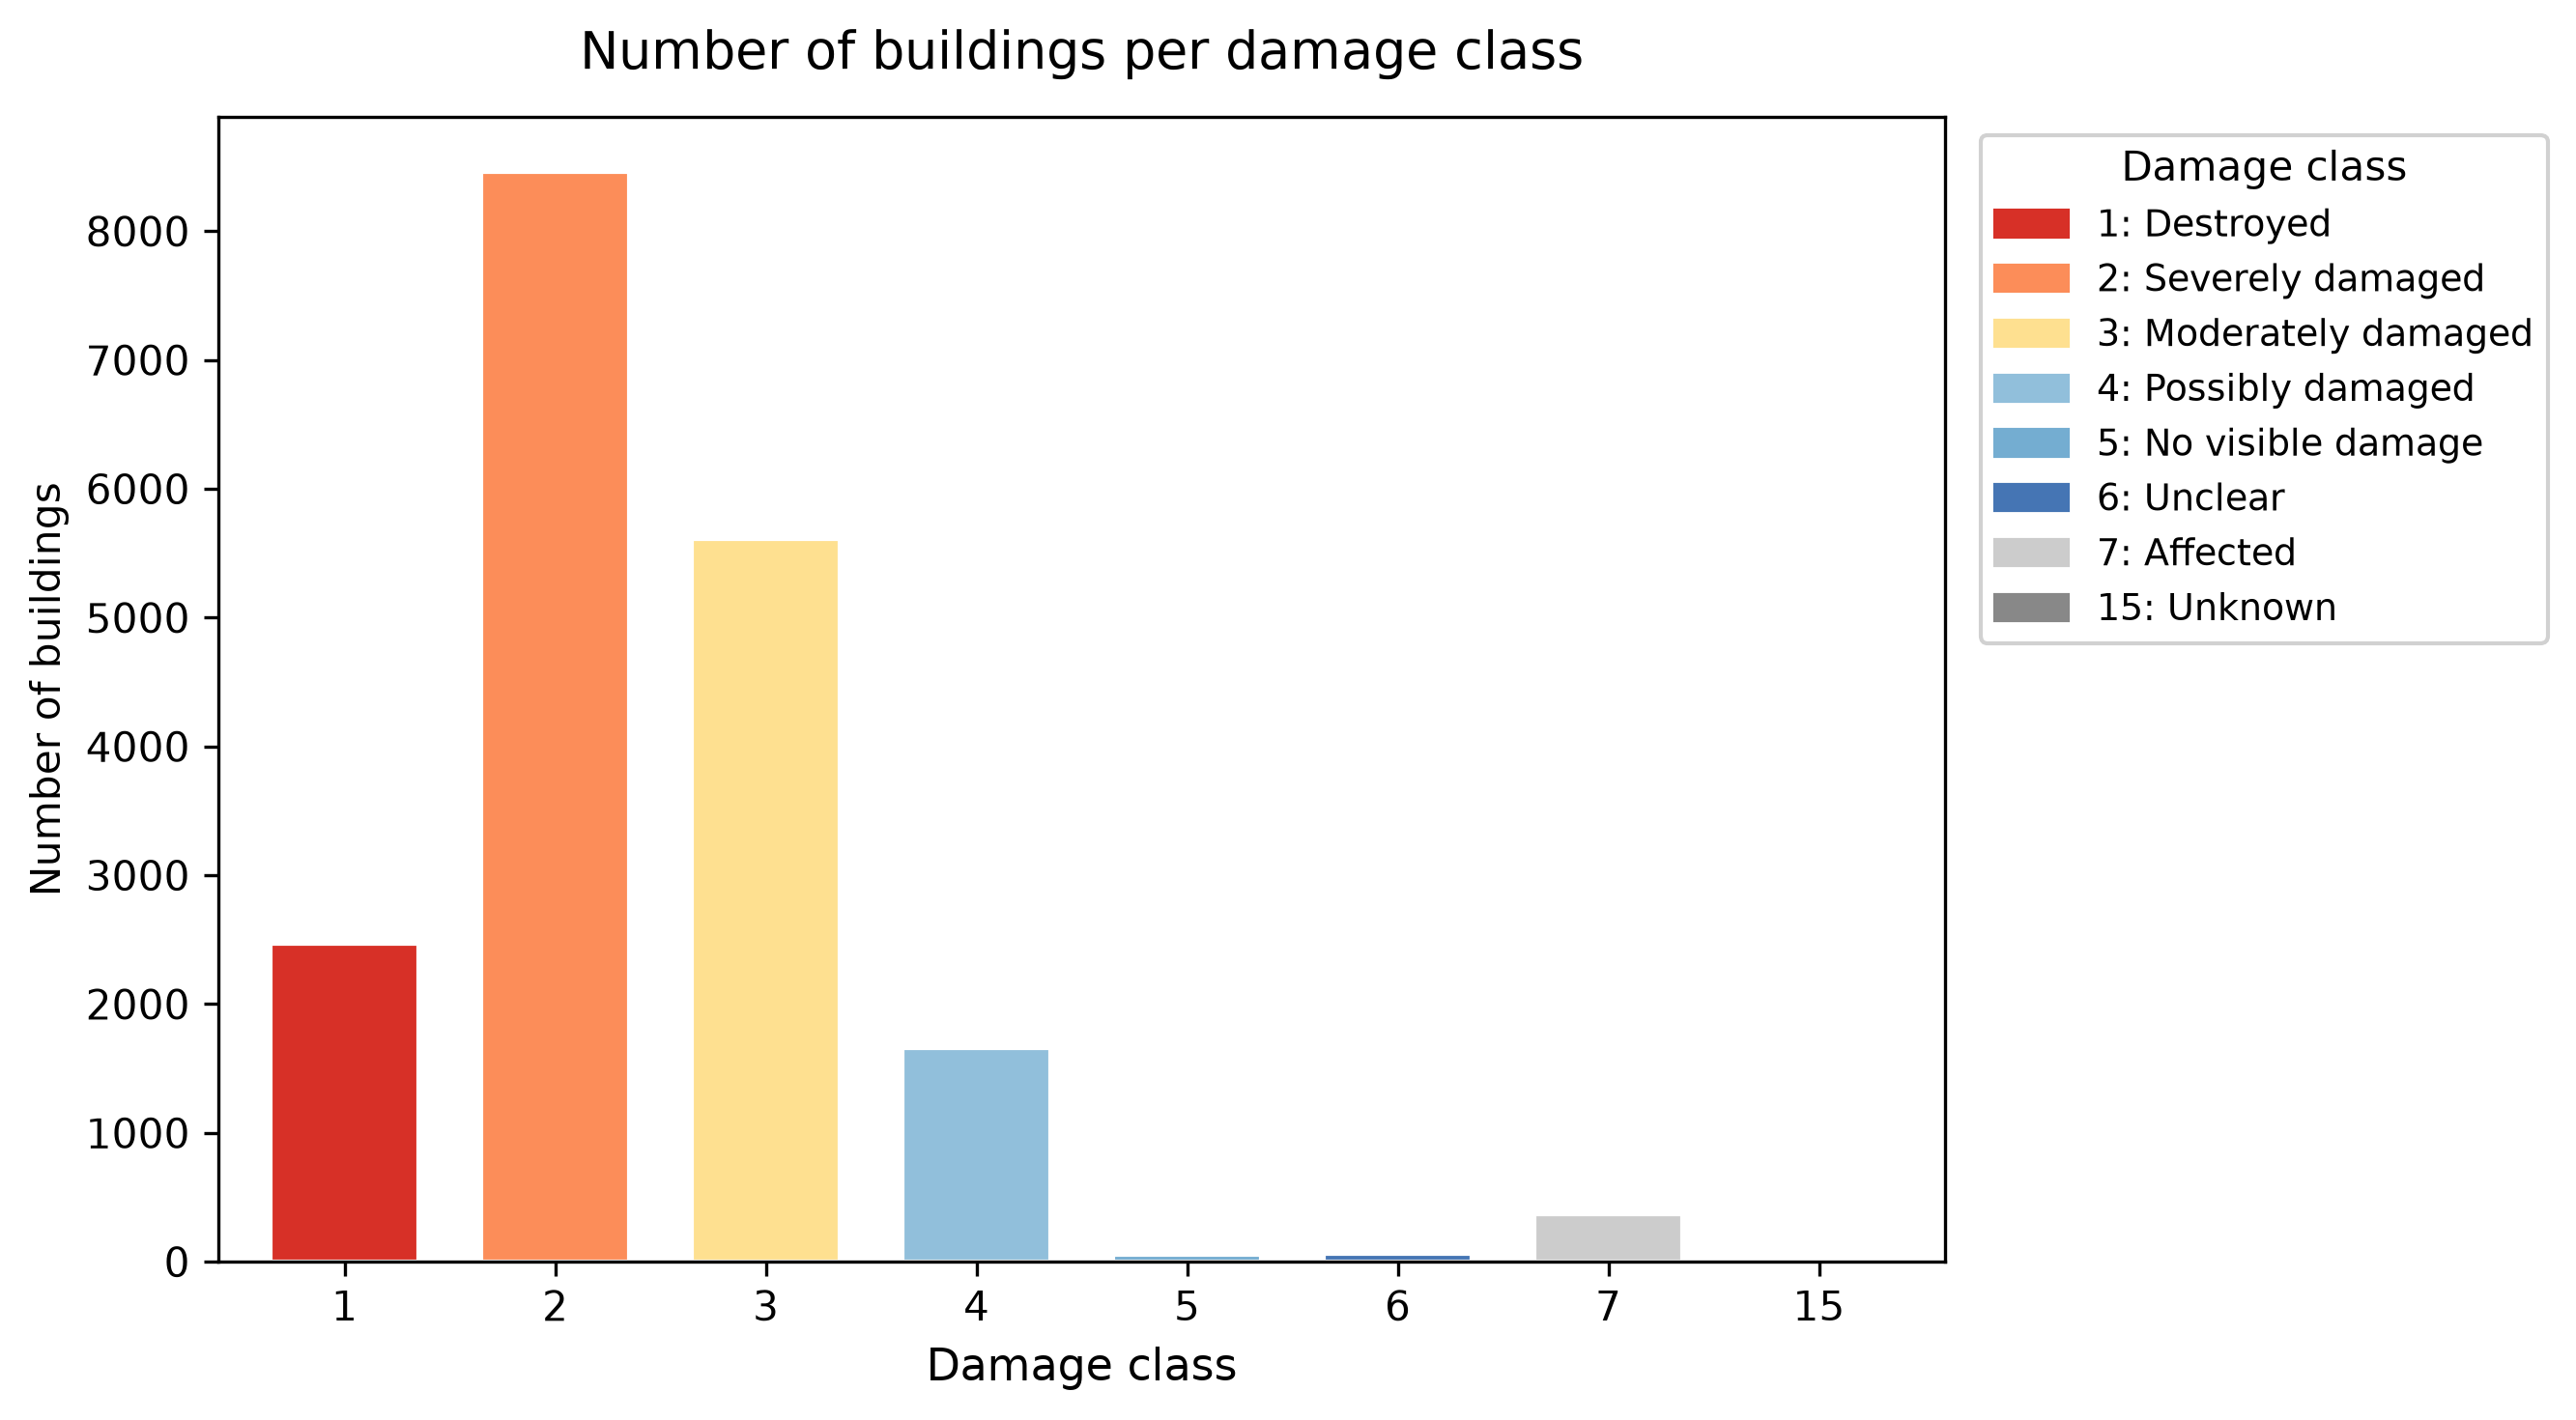

In [11]:
# Bar chart showing total labeled building count per UNOSAT damage class across Ukraine
counts = labels["damage"].value_counts().reindex(damage_classes, fill_value=0)

fig, ax = plt.subplots(figsize=(9, 5), dpi=300)

counts.plot(
    kind="bar",
    ax=ax,
    color=[color_map[c] for c in damage_classes],
    edgecolor="white",
    width=0.7
)

ax.set_title("Number of buildings per damage class", fontsize=13, pad=12)
ax.set_xlabel("Damage class", fontsize=11)
ax.set_ylabel("Number of buildings")
ax.set_xticklabels([str(c) for c in damage_classes], rotation=0)

handles = [
    mpatches.Patch(color=color_map[c], label=f"{c}: {damage_labels.get(c, str(c))}")
    for c in damage_classes
]
ax.legend(handles=handles, title="Damage class", bbox_to_anchor=(1.01, 1),
          loc="upper left", fontsize=9, framealpha=0.9)

plt.tight_layout()
plt.savefig("../outputs/figures/damage_class_distribution.png", dpi=300, bbox_inches="tight")
plt.show()

In [12]:
# Print a city-by-damage-class count table sorted by total labeled buildings
summary = (
    labels
    .groupby("city")["damage"]
    .value_counts()
    .unstack(fill_value=0)
)
summary["total"] = summary.sum(axis=1)
summary = summary.sort_values("total", ascending=False)

print(summary.to_string())

damage             1     2     3    4   5   6    7  15  total
city                                                         
Mariupol         365  2184  3102  209  33   2  198   0   6093
Rubizhne         487  1737   207  256   0   0    0   0   2687
Sievierodonetsk   92   906   321  240   2   0    0   0   1561
Lysychansk       121   539   513  229   0   0    0   0   1402
Irpin            115   698   187   60   2   0    0   0   1062
Chernihiv        266   374   256  102   7   0   27   0   1032
Volnovakha       263   541    66  108   0   0    0   0    978
Hostomel         252   129   368   70   0   0    0   0    819
Avdiivka          36   505    86    7   1   0   87   0    722
Kharkiv           56   168   241   56   3  57   28   1    610
Moschun          251   201    55   30   1   0    0   0    538
Mykolaiv          33    66    14   85   0   0    0   0    198
Borodyanka        43    55    58   10   0   0    1   0    167
Bucha             19    72    27   29   0   0    0   0    147
Makariv 

In [13]:
# Print all unique city names and AOI codes present in the labels dataset
print("Unique cities:", labels["city"].unique())
print()
print("Unique AOI codes:", labels["aoi"].unique())

Unique cities: <ArrowStringArray>
[        'Makariv',      'Borodyanka',          'Vorzel',           'Bucha',
        'Hostomel',           'Irpin', 'Antonov Airport',         'Moschun',
       'Chernihiv',        'Mykolaiv',         'Kherson',       'Antonivka',
      'Kremenchuk',            'Sumy',        'Okhtyrka',     'Trostianets',
       'Melitopol',         'Kharkiv',      'Volnovakha',      'Kramatorsk',
        'Mariupol',        'Avdiivka',        'Rubizhne',      'Lysychansk',
 'Sievierodonetsk',       'Shchastia']
Length: 26, dtype: str

Unique AOI codes: <ArrowStringArray>
[ 'UKR9',  'UKR8',  'UKR2',  'UKR6', 'UKR10', 'UKR16', 'UKR17', 'UKR12',
 'UKR15', 'UKR13', 'UKR18',  'UKR7',  'UKR4', 'UKR14',  'UKR1',  'UKR5',
  'UKR3', 'UKR11']
Length: 18, dtype: str


In [14]:
# Check how many distinct city names each AOI code maps to
labels.groupby("aoi")["city"].nunique().sort_values(ascending=False)

aoi
UKR2     6
UKR3     3
UKR16    2
UKR1     1
UKR8     1
UKR7     1
UKR6     1
UKR5     1
UKR4     1
UKR18    1
UKR10    1
UKR17    1
UKR15    1
UKR14    1
UKR13    1
UKR12    1
UKR11    1
UKR9     1
Name: city, dtype: int64

In [15]:
# Interactive stacked horizontal bar chart of labeled buildings per city, broken down by damage class
city_counts = (
    labels.groupby(["city", "damage"])
    .size()
    .unstack(fill_value=0)
    .reindex(columns=damage_classes, fill_value=0)
)
city_counts["total"] = city_counts.sum(axis=1)
city_counts = city_counts.sort_values("total", ascending=True)

fig = go.Figure()

for cls in damage_classes:
    label = damage_labels.get(cls, str(cls))
    color = color_map[cls]
    fig.add_trace(go.Bar(
        name=f"{cls}: {label}",
        y=city_counts.index,
        x=city_counts[cls],
        orientation="h",
        marker_color=color,
        hovertemplate=(
            "<b>%{y}</b><br>"
            f"Class {cls}: {label}<br>"
            "Count: %{x}<extra></extra>"
        )
    ))

for city, row in city_counts.iterrows():
    fig.add_annotation(
        x=row["total"],
        y=city,
        text=f"  {int(row['total'])}",
        showarrow=False,
        xanchor="left",
        font=dict(size=10, color="#444")
    )

fig.update_layout(
    barmode="stack",
    title=dict(text="Number of labeled buildings per city", font=dict(size=14)),
    xaxis_title="Number of buildings",
    yaxis_title="",
    legend=dict(
        title="Damage class",
        font=dict(size=10),
        bgcolor="white",
        bordercolor="#ddd",
        borderwidth=1,
        traceorder="normal"
    ),
    plot_bgcolor="white",
    paper_bgcolor="white",
    height=600,
    margin=dict(l=120, r=100, t=50, b=50),
    xaxis=dict(showgrid=True, gridcolor="#eeeeee"),
    yaxis=dict(showgrid=False)
)

for i, cls in enumerate(damage_classes):
    fig.data[i].legendrank = i

fig.show()

In [16]:
# Build an interactive Folium map of all UNOSAT damage labels across Ukraine with toggleable class layers
m = folium.Map(
    location=[48.5, 34.0],
    zoom_start=6,
    tiles="https://server.arcgisonline.com/ArcGIS/rest/services/Canvas/World_Light_Gray_Base/MapServer/tile/{z}/{y}/{x}",
    attr="Esri, HERE, Garmin, © OpenStreetMap contributors",
    control_scale=True,
    prefer_canvas=True
)

# AOI boundaries
for _, row in aois.iterrows():
    folium.GeoJson(
        row["geometry"].__geo_interface__,
        style_function=lambda x: {
            "color": "#222222",
            "weight": 2,
            "fillOpacity": 0.05,
            "fillColor": "#cccccc"
        }
    ).add_to(m)

bounds = labels.total_bounds
m.fit_bounds([[bounds[1], bounds[0]], [bounds[3], bounds[2]]])

# Damage locations
fg_varnames = {}
for cls in damage_classes:
    grp = labels[labels["damage"] == cls].copy()
    if grp.empty:
        continue
    label = damage_labels.get(cls, str(cls))
    fg = folium.FeatureGroup(name=label, show=True)
    for _, row in grp.iterrows():
        city_name = row.get("city") or "unknown"
        folium.CircleMarker(
            location=[row.geometry.y, row.geometry.x],
            radius=3,
            color=color_map[cls],
            fill=True,
            fill_color=color_map[cls],
            fill_opacity=0.85,
            weight=0.5,
            tooltip=folium.Tooltip(
                f"<b>{label}</b><br>City: {city_name}",
                sticky=False
            )
        ).add_to(fg)
    fg.add_to(m)
    fg_varnames[cls] = fg.get_name()

js_lookup = "{" + ", ".join(
    f'{cls}: "{varname}"' for cls, varname in fg_varnames.items()
) + "}"

# Legend
legend_rows = ""
for cls in damage_classes:
    if cls not in fg_varnames:
        continue
    label = damage_labels.get(cls, str(cls))
    color = color_map[cls]
    legend_rows += f"""
        <label style="display:flex;align-items:center;cursor:pointer;
                      margin-bottom:6px;gap:8px;font-size:13px;">
          <input type="checkbox" checked
                 onchange="toggleLayer(this, {cls})"
                 style="width:14px;height:14px;cursor:pointer;">
          <span style="display:inline-block;width:12px;height:12px;border-radius:50%;
                       background:{color};flex-shrink:0;"></span>
          {label}
        </label>"""

legend_html = f"""
{{% macro html(this, kwargs) %}}
<div style="
    position: fixed;
    bottom: 40px;
    left: 40px;
    z-index: 1000;
    background: white;
    padding: 14px 18px;
    border-radius: 6px;
    box-shadow: 0 1px 5px rgba(0,0,0,0.3);
    font-family: Arial, sans-serif;
    line-height: 1.4;
    min-width: 200px;
">
    {legend_rows}
    <div style="margin-top:10px;font-size:11px;color:#999;">Source: UNOSAT (2022)</div>
</div>

<script>
var layerLookup = {js_lookup};

function getMap() {{
    var keys = Object.keys(window).filter(function(k) {{
        return window[k] instanceof L.Map;
    }});
    return keys.length > 0 ? window[keys[0]] : null;
}}

function toggleLayer(checkbox, cls) {{
    var map = getMap();
    if (!map) {{ console.log("map not found"); return; }}

    var varname = layerLookup[cls];
    var layer = window[varname];
    if (!layer) {{ console.log("layer not found:", varname); return; }}

    if (checkbox.checked) {{
        map.addLayer(layer);
    }} else {{
        map.removeLayer(layer);
    }}
}}
</script>
{{% endmacro %}}
"""

legend = MacroElement()
legend._template = Template(legend_html)
m.get_root().add_child(legend)

m.save("../outputs/figures/UNOSAT_label_map.html")

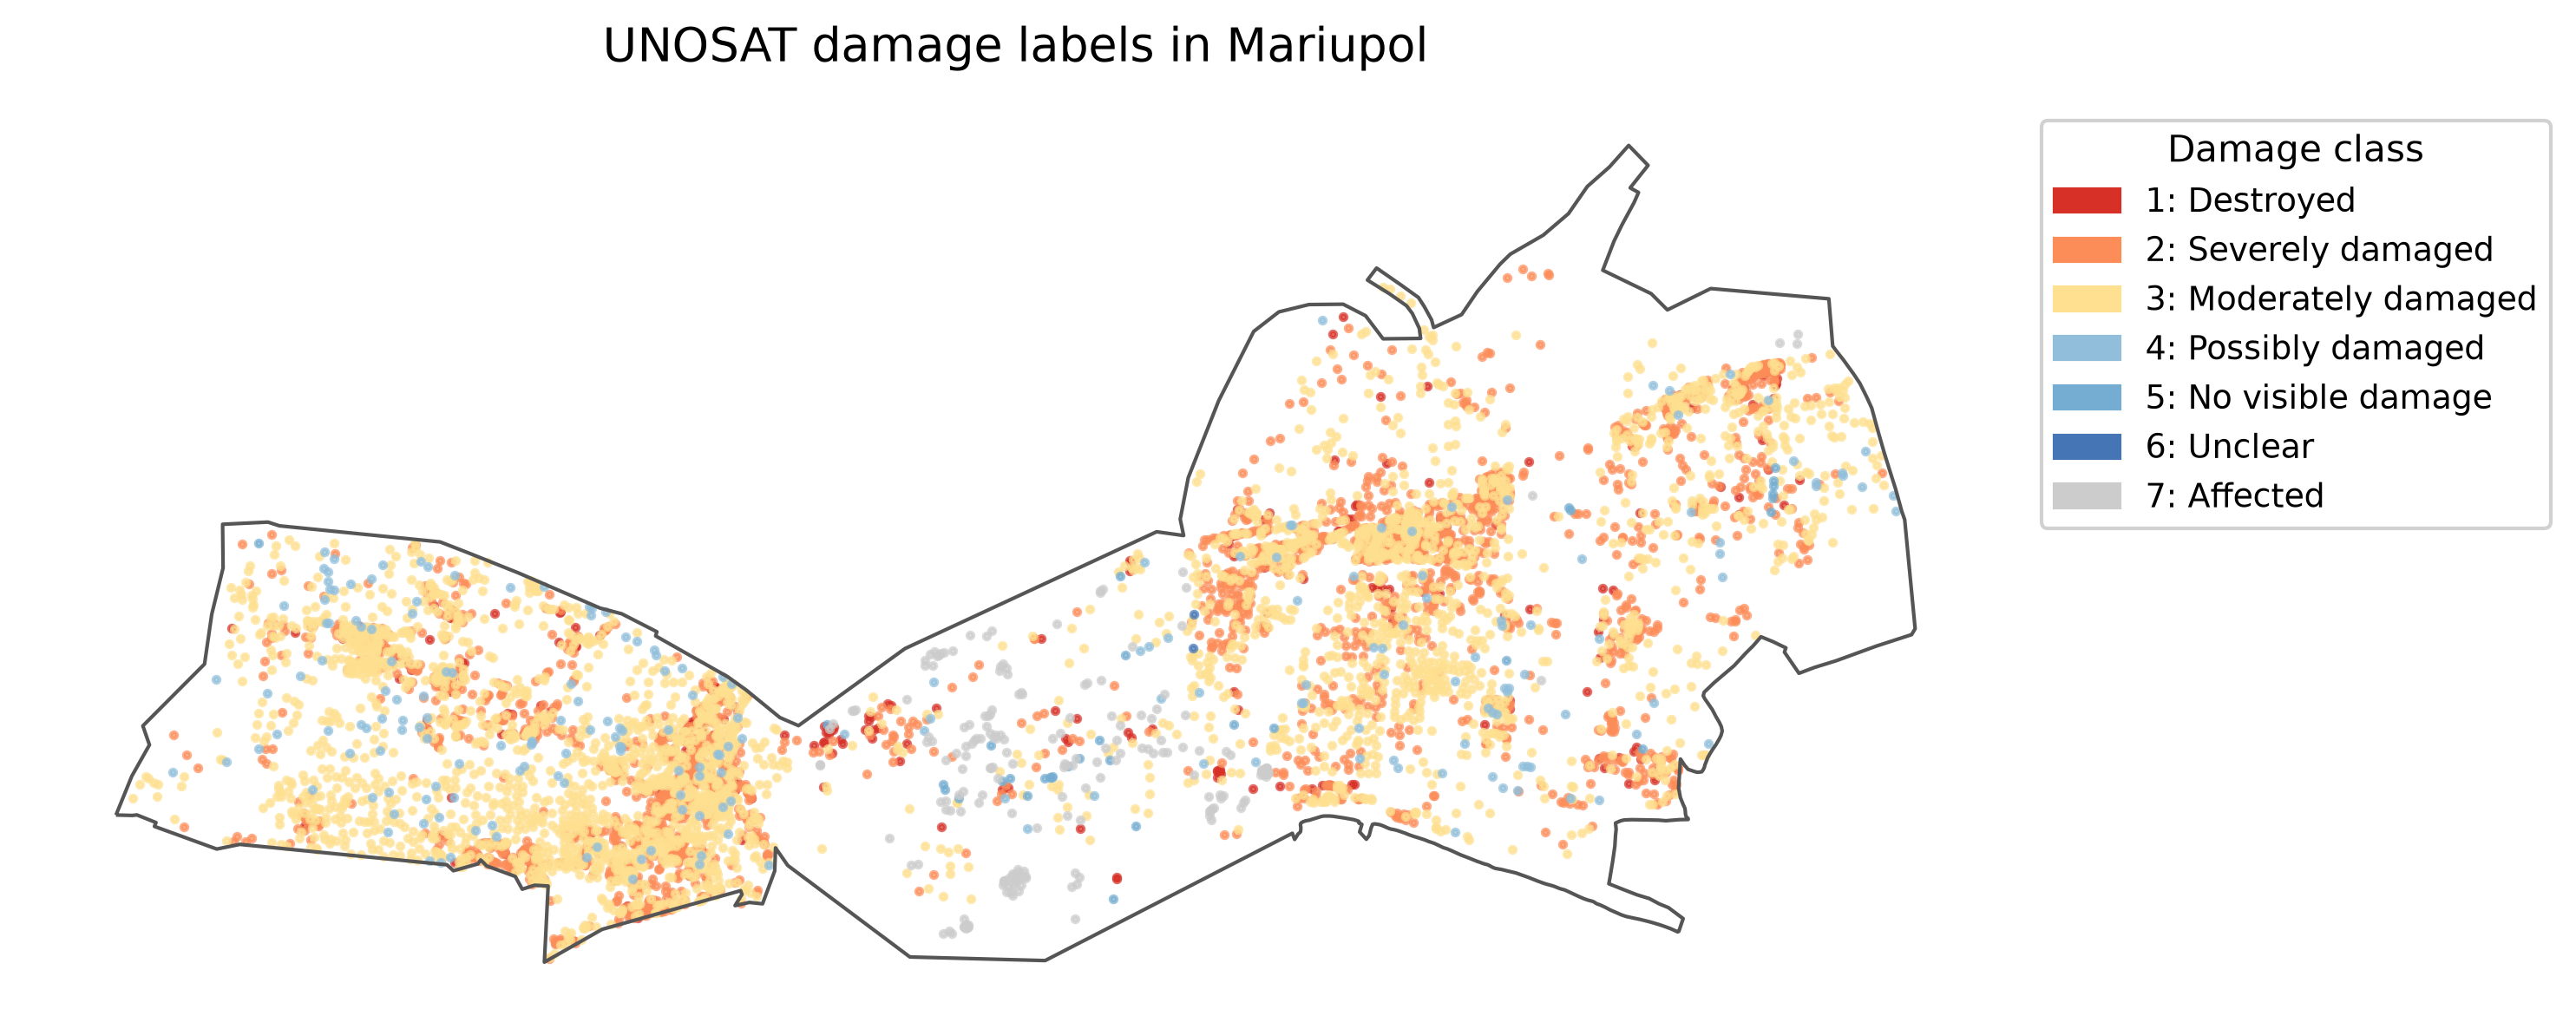

In [17]:
# Map of UNOSAT damage labels within the Mariupol AOI boundary
city_aoi = aois[aois["city"] == "Mariupol"]
city_labels = labels[labels["city"] == "Mariupol"]

fig, ax = plt.subplots(figsize=(10, 8), dpi=300)
city_aoi.boundary.plot(ax=ax, color="#555555", linewidth=1)

for cls in damage_classes:
    grp = city_labels[city_labels["damage"] == cls]
    if grp.empty:
        continue
    grp.plot(ax=ax, markersize=3, color=color_map[cls], alpha=0.7)

handles = [
    mpatches.Patch(color=color_map[c], label=f"{c}: {damage_labels.get(c, str(c))}")
    for c in damage_classes if c in city_labels["damage"].values
]
ax.legend(handles=handles, title="Damage class", bbox_to_anchor=(1.01, 1),
          loc="upper left", fontsize=9, framealpha=0.9)
ax.set_title(f"UNOSAT damage labels in Mariupol", fontsize=13, pad=12)
ax.set_axis_off()
plt.tight_layout()
plt.savefig(f"../outputs/figures/map_mariupol.png", dpi=300, bbox_inches="tight")
plt.show()

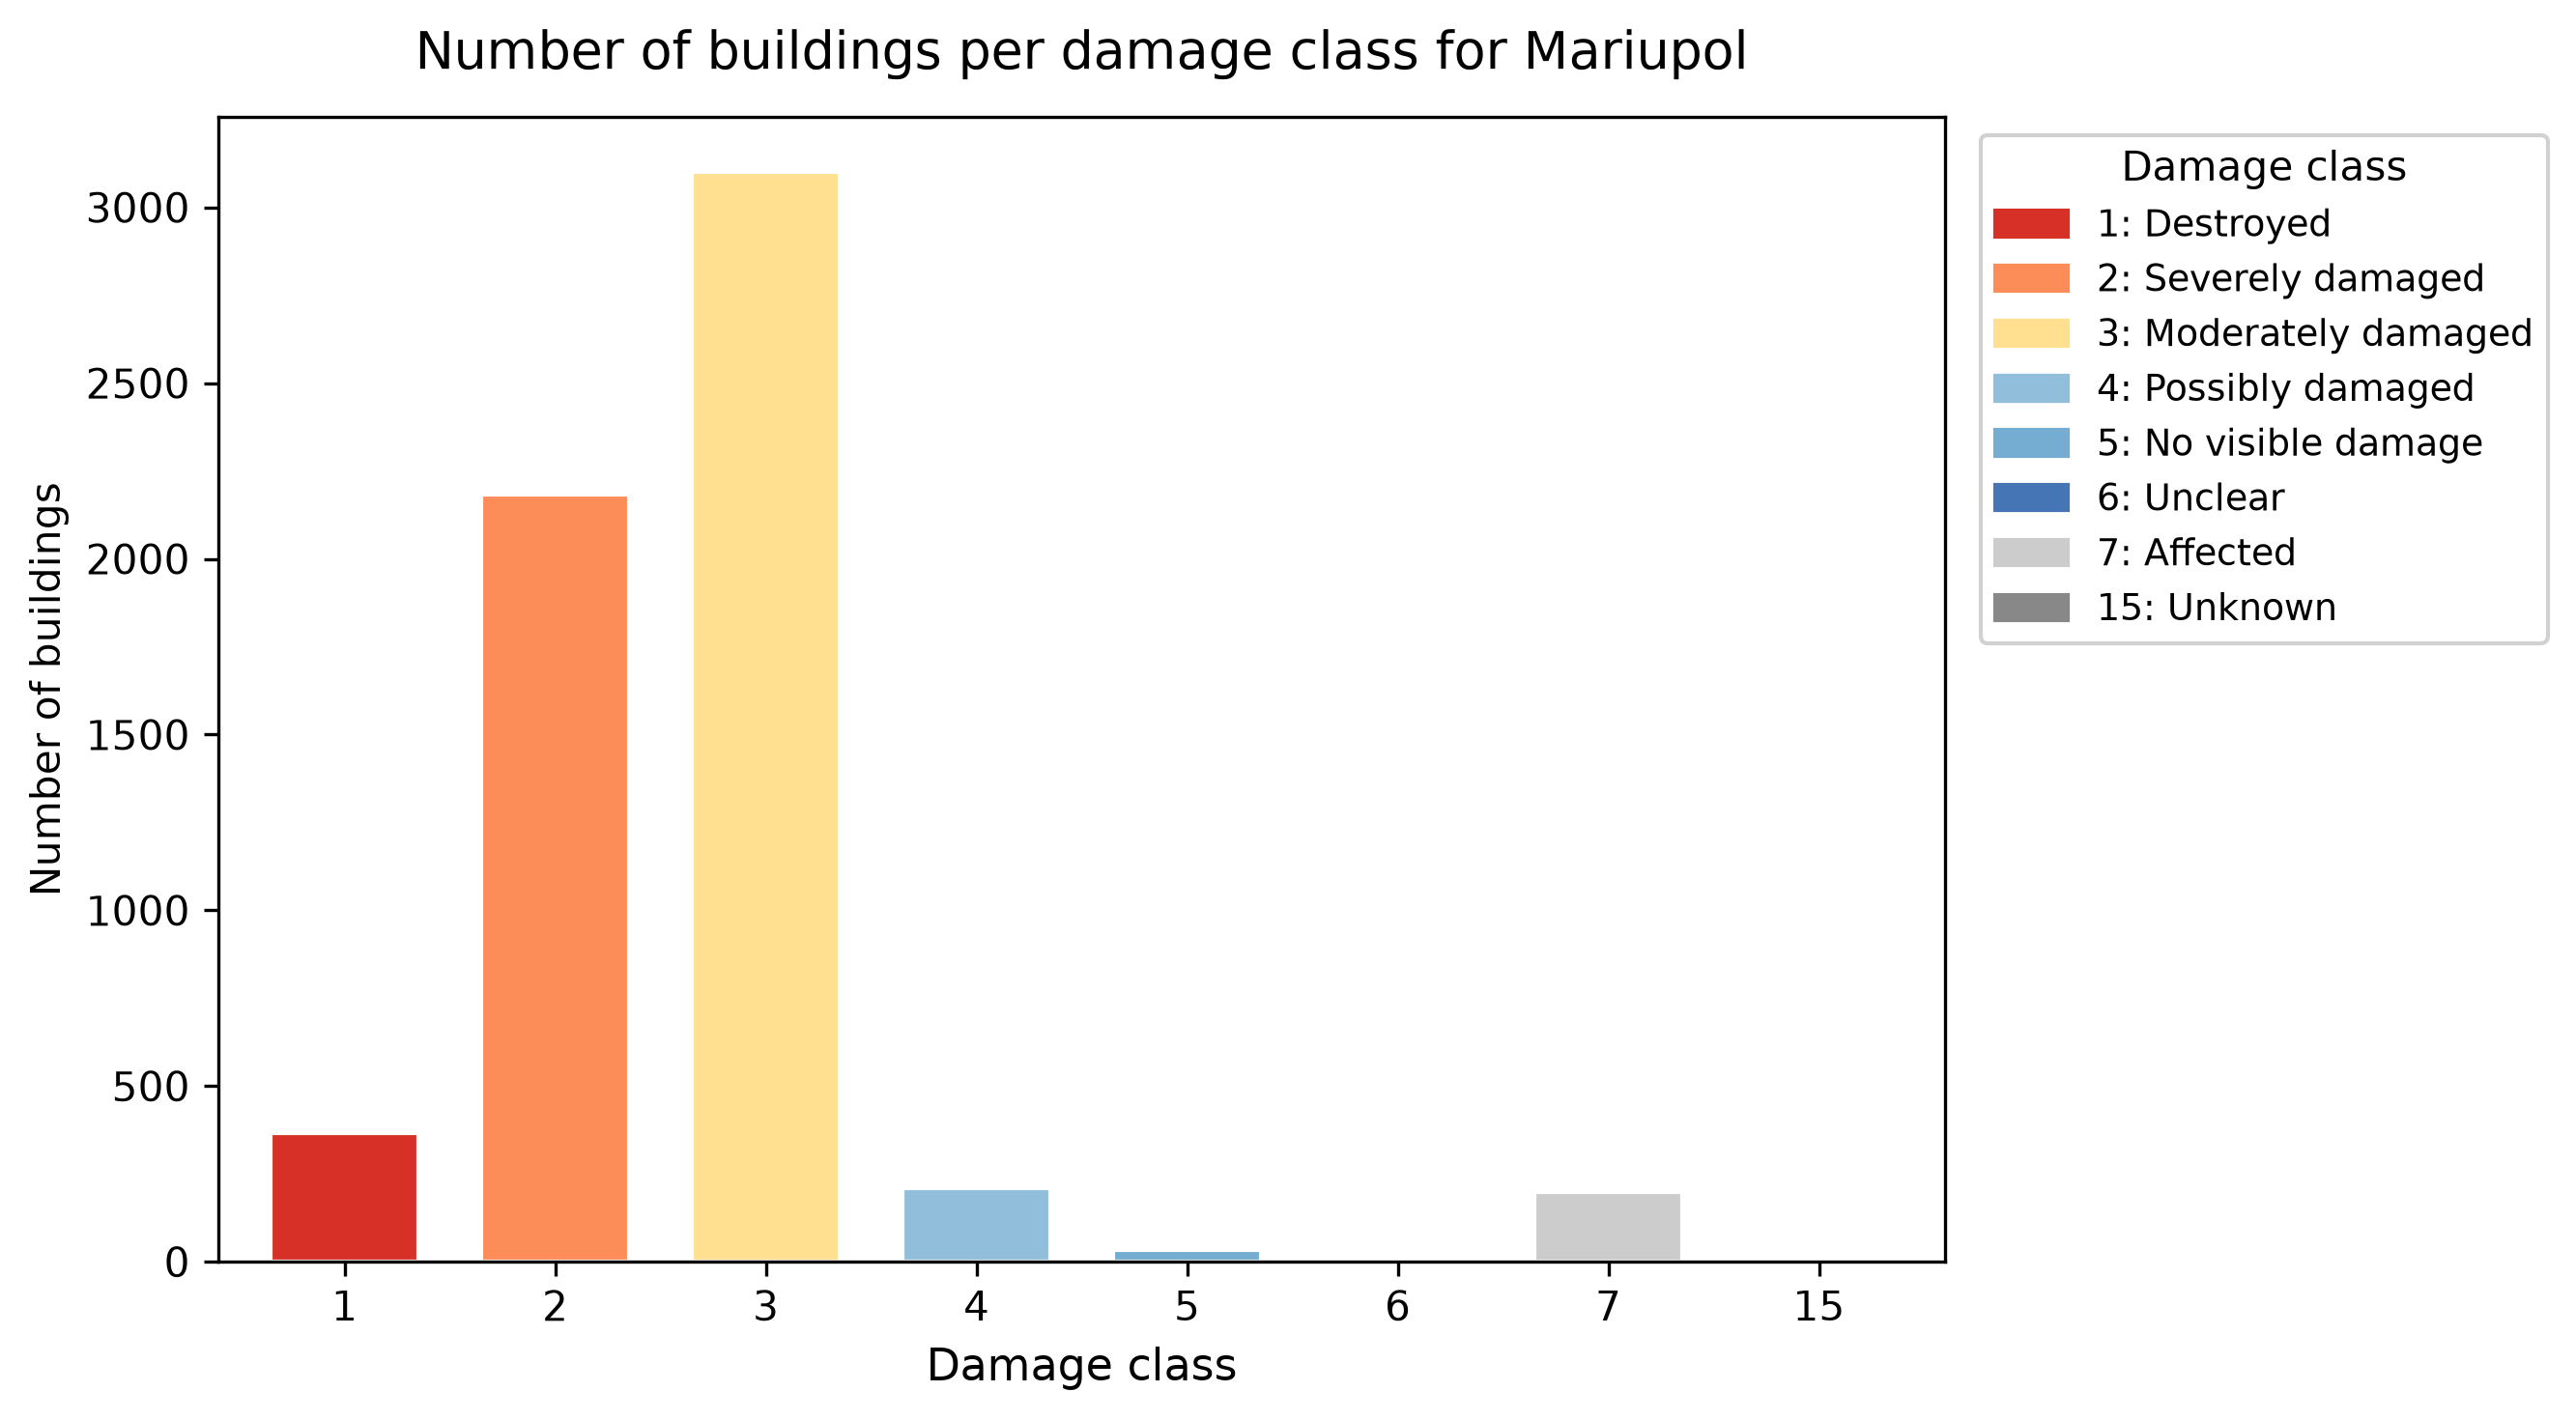

In [18]:
# Bar chart of damage class distribution for Mariupol buildings only
counts = city_labels["damage"].value_counts().reindex(damage_classes, fill_value=0)

fig, ax = plt.subplots(figsize=(9, 5), dpi=300)
counts.plot(kind="bar", ax=ax, color=[color_map[c] for c in damage_classes],
            edgecolor="white", width=0.7)

ax.set_title(f"Number of buildings per damage class for Mariupol", fontsize=13, pad=12)
ax.set_xlabel("Damage class", fontsize=11)
ax.set_ylabel("Number of buildings")
ax.set_xticklabels([str(c) for c in damage_classes], rotation=0)

handles = [mpatches.Patch(color=color_map[c], label=f"{c}: {damage_labels.get(c, str(c))}")
           for c in damage_classes]
ax.legend(handles=handles, title="Damage class", bbox_to_anchor=(1.01, 1),
          loc="upper left", fontsize=9, framealpha=0.9)

plt.tight_layout()
plt.savefig(f"../outputs/figures/damage_class_distribution_mariupol.png",
            dpi=300, bbox_inches="tight")
plt.show()